# Step 1 - ANN

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [4]:
df = pd.read_csv("diabetes.csv")

print("Dataset shape:", df.shape)
display(df.head(5))

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

Missing values in each column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome         

In [6]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("Zero counts before replacement:")
print((df[zero_columns] == 0).sum())

for column in zero_columns:
    median_value = df.loc[df[column] != 0, column].median()
    df.loc[df[column] == 0, column] = median_value

print("\nZero counts after replacement:")
print((df[zero_columns] == 0).sum())

Zero counts before replacement:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Zero counts after replacement:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [7]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (768, 8)
Target shape: (768,)

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (614, 8)
Testing features: (154, 8)


In [9]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

print("ANN model created successfully!")

ANN model created successfully!


In [10]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6538 - loss: 0.6417 - val_accuracy: 0.6423 - val_loss: 0.6595
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6578 - loss: 0.6176 - val_accuracy: 0.6504 - val_loss: 0.6332
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6599 - loss: 0.5954 - val_accuracy: 0.6748 - val_loss: 0.6088
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6843 - loss: 0.5743 - val_accuracy: 0.6829 - val_loss: 0.5878
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6843 - loss: 0.5560 - val_accuracy: 0.7073 - val_loss: 0.5684
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7088 - loss: 0.5389 - val_accuracy: 0.7154 - val_loss: 0.5509
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7169 - loss: 0.5231 - val_accuracy: 0.7398 - val_loss: 0.5341
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7312 - loss: 0.5091 - val_accuracy: 0.7154 - val_loss

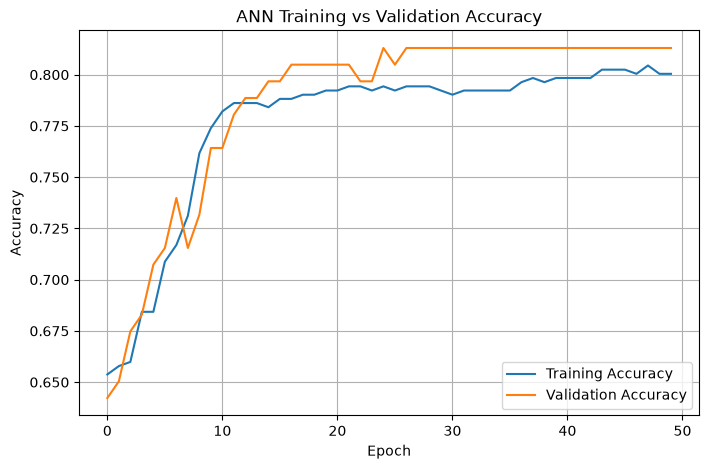

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

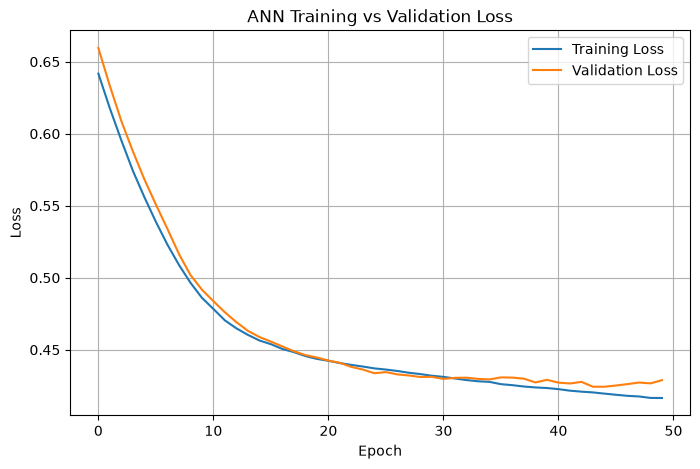

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ANN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.4956
Test Accuracy: 74.03%


In [18]:
y_probability = model.predict(X_test, verbose=0)
y_pred = (y_probability >= 0.5).astype(int).ravel()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Precision:     {precision:.4f}")
print(f"Recall:        {recall:.4f}")
print(f"F1-Score:      {f1:.4f}")

Test Accuracy: 0.7403
Precision:     0.6400
Recall:        0.5926
F1-Score:      0.6154


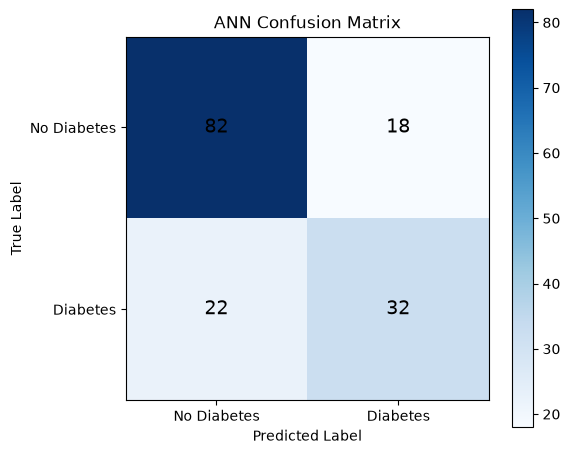

              precision    recall  f1-score   support

 No Diabetes       0.79      0.82      0.80       100
    Diabetes       0.64      0.59      0.62        54

    accuracy                           0.74       154
   macro avg       0.71      0.71      0.71       154
weighted avg       0.74      0.74      0.74       154



In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.yticks([0, 1], ["No Diabetes", "Diabetes"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)

plt.colorbar()
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"],
    zero_division=0
))

In [20]:
model.save("ann_diabetes_model.h5")
print("ANN model saved successfully!")

ANN model saved successfully!


### ANN Reflection

- **Input layer:** Accepts eight patient features used to predict diabetes.
- **First hidden layer:** Uses 16 neurons with ReLU activation to learn patterns in the input data.
- **Second hidden layer:** Uses 8 neurons to learn more compact feature representations.
- **Choice of neurons:** The 16-and-8 architecture provides a small network suitable for a basic binary classification task.
- **Output layer:** One neuron with sigmoid activation produces a probability between 0 and 1. A threshold of 0.5 converts it into a predicted class.
- **Optimizer and loss:** Adam updates the model weights, while binary cross-entropy measures prediction error.
- **Evaluation:** Test accuracy, precision, recall, F1-score, and the confusion matrix measure performance on unseen data.

# Step 2 - OpenCV

In [23]:
pip install opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.


In [24]:
import cv2
import os
import matplotlib.pyplot as plt
import numpy as np

print("OpenCV version:", cv2.__version__)
print("OpenCV libraries imported successfully!")

OpenCV version: 5.0.0
OpenCV libraries imported successfully!


images/Cars.jpeg: Height=2304, Width=4096, Channels=3
images/Deadpool.jpg: Height=4320, Width=7680, Channels=3
images/Power Rangers.jpeg: Height=2160, Width=3840, Channels=3
images/Spiderman N Venom.jpg: Height=1080, Width=1928, Channels=3
images/Luffy.png: Height=2242, Width=4000, Channels=3


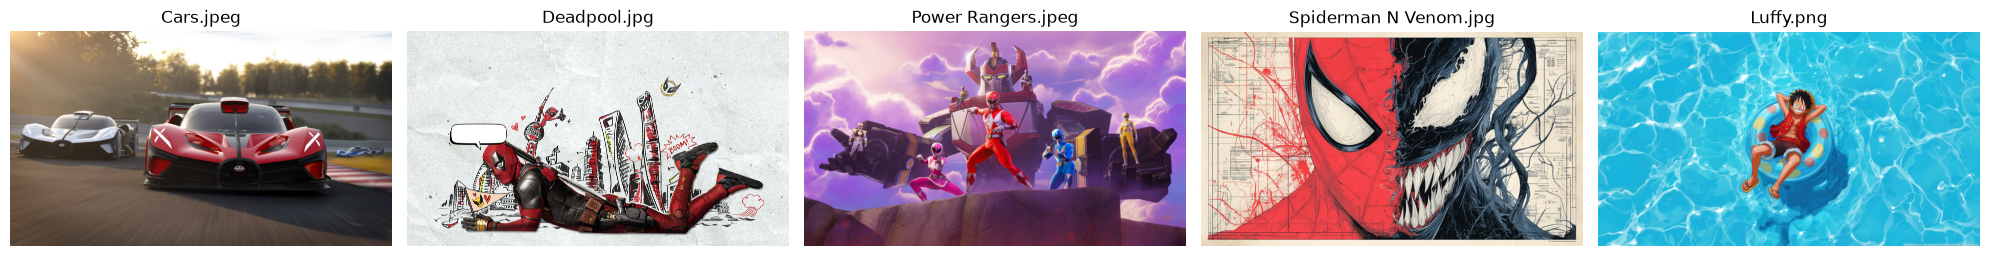

In [27]:
image_paths = [
    "images/Cars.jpeg",
    "images/Deadpool.jpg",
    "images/Power Rangers.jpeg",
    "images/Spiderman N Venom.jpg",
    "images/Luffy.png"
]

images = []

for path in image_paths:
    img = cv2.imread(path)

    if img is None:
        raise FileNotFoundError(
            f"Cannot load {path}. Check the filename and images folder."
        )

    images.append(img)

    height, width, channels = img.shape
    print(f"{path}: Height={height}, Width={width}, Channels={channels}")

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, img, path in zip(axes, images, image_paths):
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb)
    ax.set_title(os.path.basename(path))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
os.makedirs("outputs", exist_ok=True)

processed_images = []

for i, img in enumerate(images):
    # 1. Resize to 128 x 128
    resized = cv2.resize(img, (128, 128))

    # 2. Convert to grayscale
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

    # 3. Apply Gaussian blur (5 x 5)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 4. Detect edges using Canny
    edges = cv2.Canny(blurred, 100, 200)

    # 5. Find contours and draw the largest bounding rectangle
    contours, _ = cv2.findContours(
        edges.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    contour_img = resized.copy()

    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)

        cv2.rectangle(
            contour_img,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    processed_images.append({
        "original": img,
        "resized": resized,
        "gray": gray,
        "blurred": blurred,
        "edges": edges,
        "contour": contour_img
    })

    # Save the original and all preprocessing results
    name = os.path.splitext(os.path.basename(image_paths[i]))[0]

    cv2.imwrite(f"outputs/{name}_original.jpg", img)
    cv2.imwrite(f"outputs/{name}_resized.jpg", resized)
    cv2.imwrite(f"outputs/{name}_grayscale.jpg", gray)
    cv2.imwrite(f"outputs/{name}_blurred.jpg", blurred)
    cv2.imwrite(f"outputs/{name}_edges.jpg", edges)
    cv2.imwrite(f"outputs/{name}_contour.jpg", contour_img)

print("Preprocessing completed!")
print("Saved original and processed images in the outputs folder.")

Preprocessing completed!
Saved original and processed images in the outputs folder.


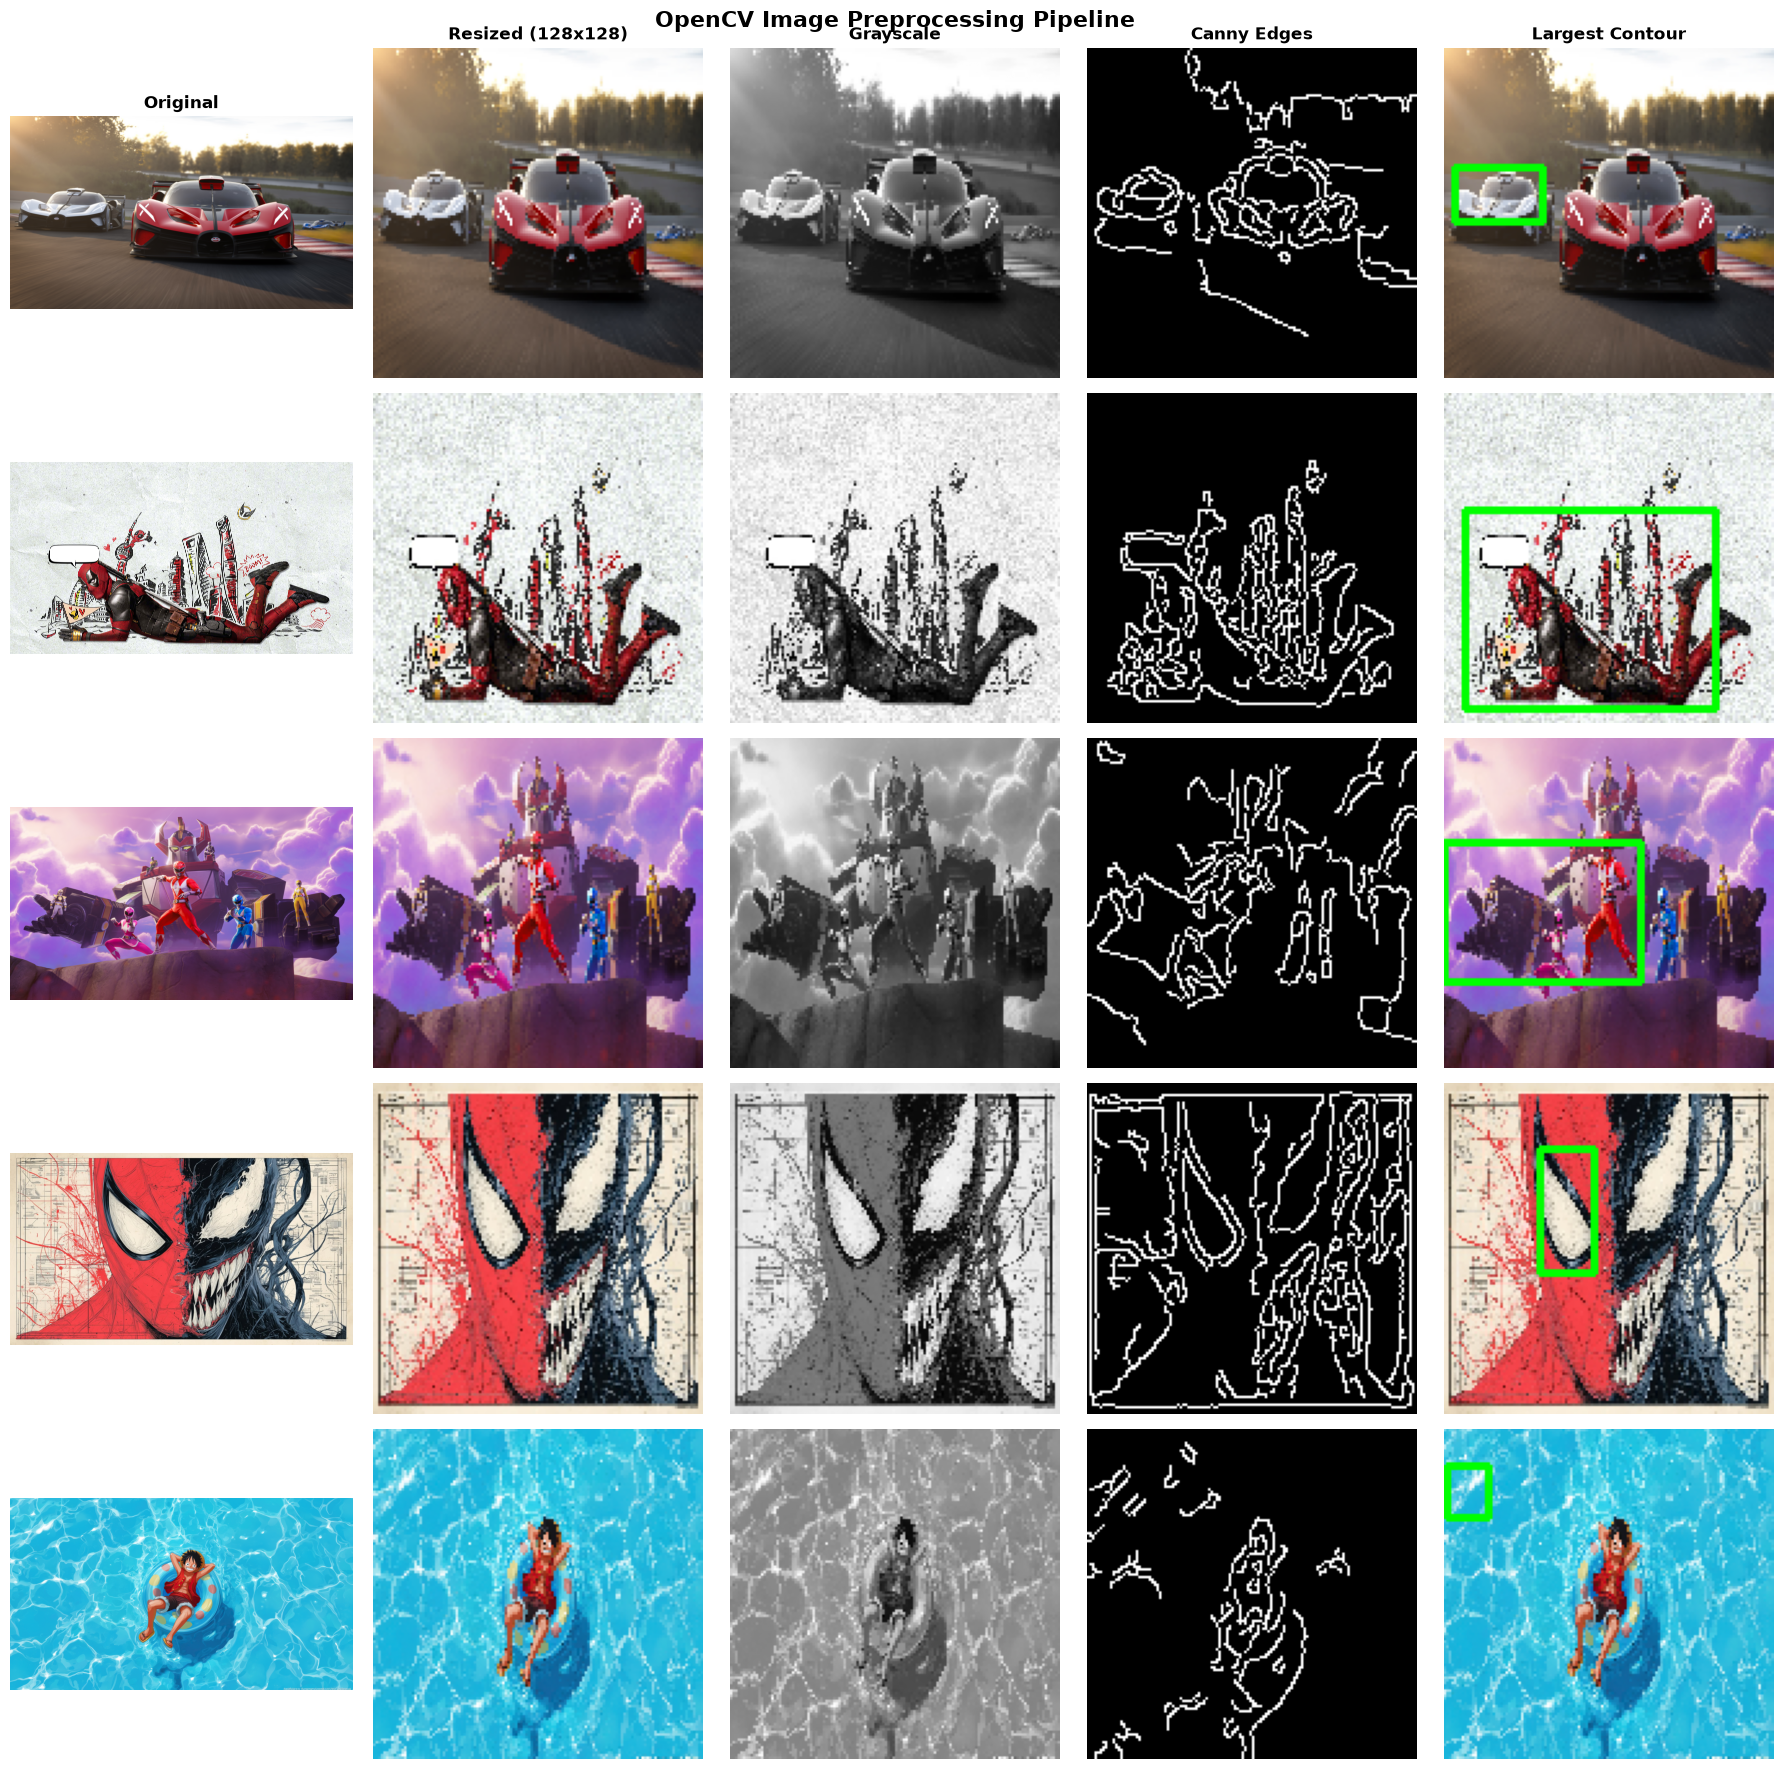

5x5 grid saved to outputs/opencv_5x5_grid.png


In [29]:
fig, axes = plt.subplots(5, 5, figsize=(18, 18))

column_titles = [
    "Original",
    "Resized (128x128)",
    "Grayscale",
    "Canny Edges",
    "Largest Contour"
]

for col, title in enumerate(column_titles):
    axes[0, col].set_title(title, fontsize=12, fontweight="bold")

for row, result in enumerate(processed_images):
    # Convert BGR images to RGB for display
    original_rgb = cv2.cvtColor(result["original"], cv2.COLOR_BGR2RGB)
    resized_rgb = cv2.cvtColor(result["resized"], cv2.COLOR_BGR2RGB)
    contour_rgb = cv2.cvtColor(result["contour"], cv2.COLOR_BGR2RGB)

    display_images = [
        original_rgb,
        resized_rgb,
        result["gray"],
        result["edges"],
        contour_rgb
    ]

    for col, display_img in enumerate(display_images):
        axes[row, col].imshow(
            display_img,
            cmap="gray" if col in [2, 3] else None
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        os.path.basename(image_paths[row]),
        fontsize=10
    )

plt.suptitle(
    "OpenCV Image Preprocessing Pipeline",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.savefig("outputs/opencv_5x5_grid.png", dpi=150, bbox_inches="tight")
plt.show()

print("5x5 grid saved to outputs/opencv_5x5_grid.png")

### Step 2: OpenCV Image Preprocessing

**Objective:** Apply preprocessing techniques to five images using OpenCV.

- **Loading:** Read and display images using `cv2.imread()`.
- **Resizing:** Resize images to 128×128 pixels.
- **Grayscale:** Convert images to grayscale.
- **Gaussian Blur:** Reduce image noise using a 5×5 kernel.
- **Canny Edge Detection:** Detect image edges.
- **Contour Detection:** Draw a green rectangle around the largest contour.

**Result:** Display a 5×5 grid and save processed images in the `outputs` folder.

# Step 3 - CNN

In [9]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

print("Libraries imported successfully!")

Libraries imported successfully!


In [24]:
import os

dataset_dir = r"C:\Users\patel\OneDrive\Desktop\R&W\Deep Learning\Deep learning practical exam set A\cifar-10-batches-py"

print("Folder exists:", os.path.isdir(dataset_dir))
print("Files:", os.listdir(dataset_dir) if os.path.isdir(dataset_dir) else "Folder not found")

Folder exists: True
Files: ['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']


In [25]:
import pickle
import numpy as np

def load_cifar_batch(file_path):
    with open(file_path, "rb") as f:
        batch = pickle.load(f, encoding="bytes")

    images = batch[b"data"].reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)
    labels = np.array(batch[b"labels"])

    return images, labels

X_train_list, y_train_list = [], []

for i in range(1, 6):
    X_batch, y_batch = load_cifar_batch(
        os.path.join(dataset_dir, f"data_batch_{i}")
    )
    X_train_list.append(X_batch)
    y_train_list.append(y_batch)

X_train = np.concatenate(X_train_list)[:20000]
y_train = np.concatenate(y_train_list)[:20000]

X_test, y_test = load_cifar_batch(
    os.path.join(dataset_dir, "test_batch")
)

X_test = X_test[:4000]
y_test = y_test[:4000]

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (20000, 32, 32, 3)
Testing images: (4000, 32, 32, 3)


In [27]:
from tensorflow.keras.utils import to_categorical

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print("Normalization and one-hot encoding completed!")

Normalization and one-hot encoding completed!


Shape: (10000, 32, 32, 3)
Minimum pixel: 0
Maximum pixel: 255
First image unique values: [ 0  4  5  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


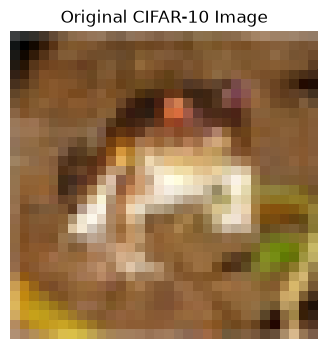

In [35]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

# Reload the original CIFAR-10 training batch
file_path = os.path.join(dataset_dir, "data_batch_1")

with open(file_path, "rb") as f:
    batch = pickle.load(f, encoding="bytes")

# Restore the original pixel values (0–255)
X_check = batch[b"data"].reshape(-1, 3, 32, 32)
X_check = X_check.transpose(0, 2, 3, 1)

print("Shape:", X_check.shape)
print("Minimum pixel:", X_check.min())
print("Maximum pixel:", X_check.max())
print("First image unique values:", np.unique(X_check[0])[:20])

# Display the original image
plt.figure(figsize=(4, 4))
plt.imshow(X_check[0])
plt.title("Original CIFAR-10 Image")
plt.axis("off")
plt.show()

In [36]:
X_train_list, y_train_list = [], []

for i in range(1, 6):
    file_path = os.path.join(dataset_dir, f"data_batch_{i}")

    with open(file_path, "rb") as f:
        batch = pickle.load(f, encoding="bytes")

    images = batch[b"data"].reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)

    X_train_list.append(images)
    y_train_list.extend(batch[b"labels"])

X_train = np.concatenate(X_train_list)[:20000]
y_train = np.array(y_train_list[:20000])

X_test, y_test = load_cifar_batch(
    os.path.join(dataset_dir, "test_batch")
)

X_test = X_test[:4000]
y_test = y_test[:4000]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())

Training: (20000, 32, 32, 3)
Testing: (4000, 32, 32, 3)
Pixel range: 0 to 255


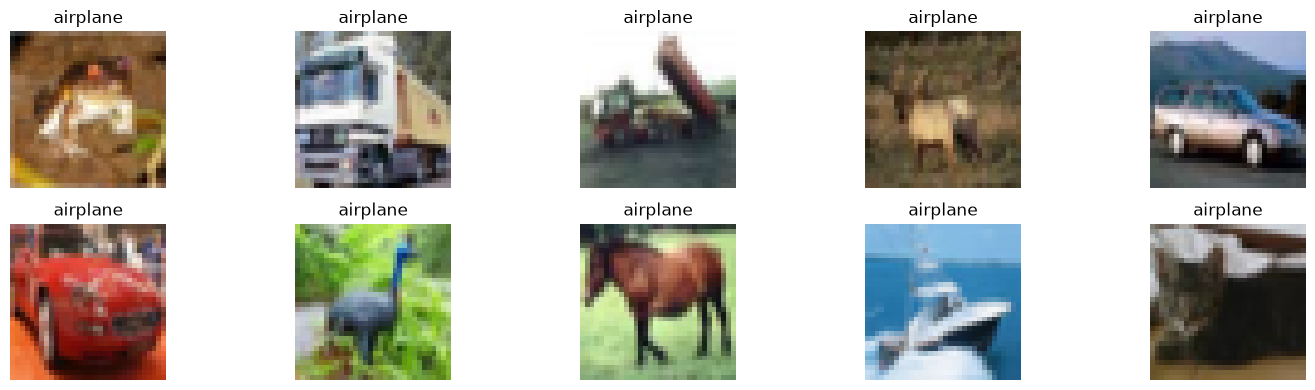

In [37]:
plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[np.argmax(y_train[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [44]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense
)

cnn_model = Sequential([
    Input(shape=(32, 32, 3)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (20000, 32, 32, 3)
y_train: (20000, 10)
X_test: (4000, 32, 32, 3)
y_test: (4000, 10)


In [46]:
cnn_history = cnn_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.2774 - loss: 3.0765 - val_accuracy: 0.3735 - val_loss: 1.7544
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.4330 - loss: 1.5622 - val_accuracy: 0.4245 - val_loss: 1.6103
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5051 - loss: 1.3730 - val_accuracy: 0.4810 - val_loss: 1.4745
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5712 - loss: 1.2113 - val_accuracy: 0.5135 - val_loss: 1.4099
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6170 - loss: 1.0818 - val_accuracy: 0.5285 - val_loss: 1.4032
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6694 - loss: 0.9415 - val_accuracy: 0.5295 - val_loss: 1.5084
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7043 - loss: 0.8365 - val_accuracy: 0.5315 - val_loss: 1.5573
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7428 - loss: 0.7424 - val_accuracy: 0.

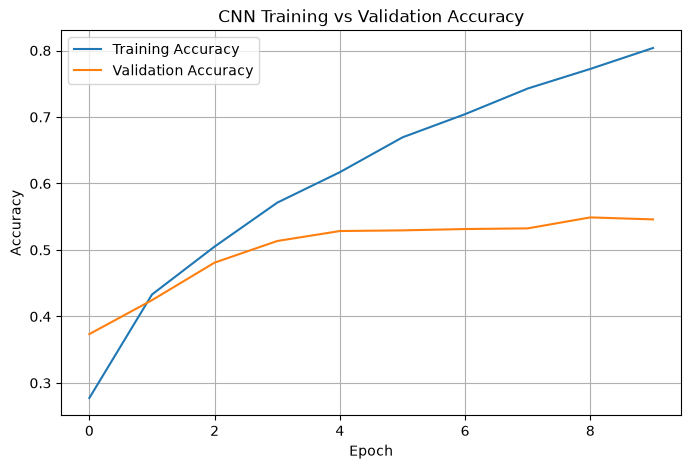

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

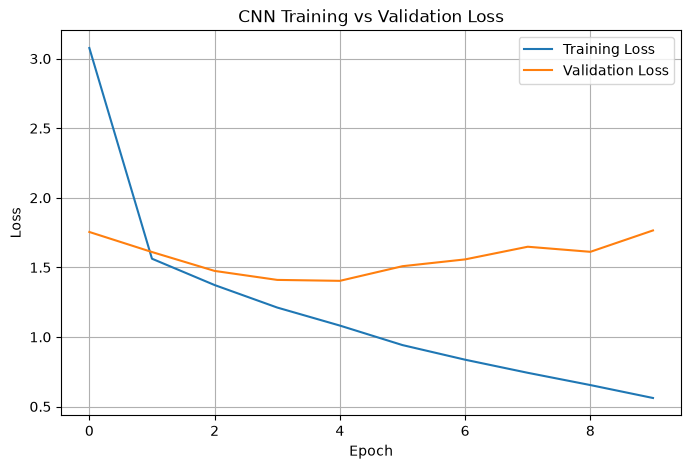

In [49]:
plt.figure(figsize=(8, 5))
plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [52]:
test_loss, test_accuracy = cnn_model.evaluate(
    X_test, y_test, verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5445 - loss: 1.7732
Test Loss: 1.7732
Test Accuracy: 54.45%


In [53]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(cnn_model.predict(X_test, verbose=0), axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

    airplane       0.62      0.49      0.54       389
  automobile       0.69      0.61      0.64       392
        bird       0.43      0.40      0.41       426
         cat       0.44      0.36      0.40       389
        deer       0.39      0.58      0.47       400
         dog       0.48      0.39      0.43       388
        frog       0.56      0.74      0.64       396
       horse       0.59      0.62      0.61       397
        ship       0.69      0.64      0.66       408
       truck       0.63      0.60      0.62       415

    accuracy                           0.54      4000
   macro avg       0.55      0.54      0.54      4000
weighted avg       0.55      0.54      0.54      4000



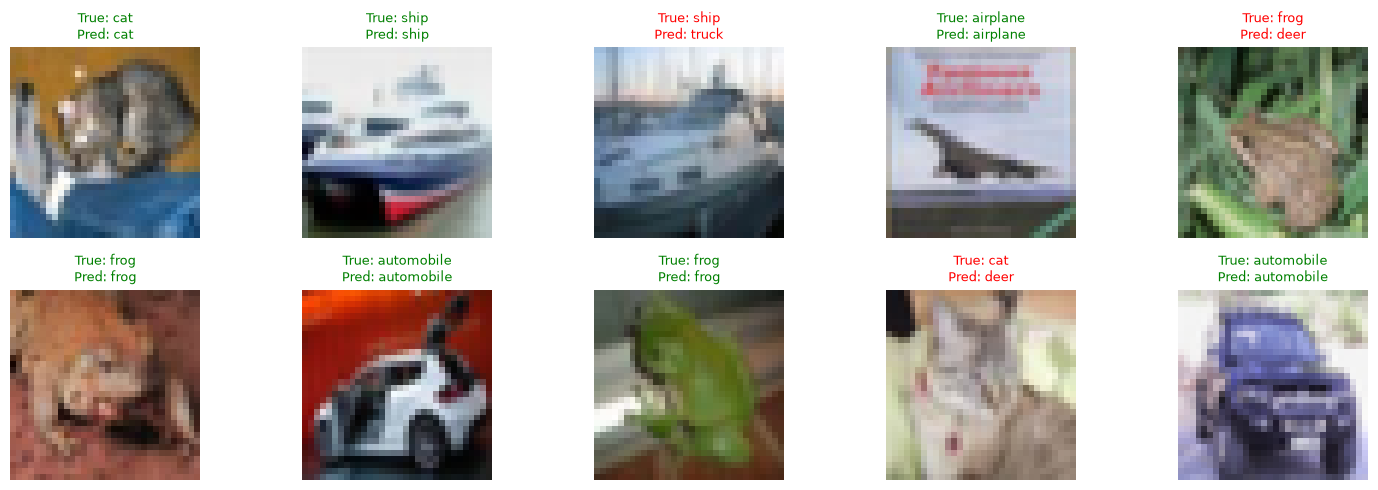

In [54]:
plt.figure(figsize=(15, 5))

for i in range(10):
    true_label = y_true[i]
    predicted_label = y_pred[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])
    plt.title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}",
        color="green" if true_label == predicted_label else "red",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [55]:
cnn_model.save("cnn_cifar10_model.h5")

print("CNN model saved successfully!")

CNN model saved successfully!


### 3.4 Save & Reflect

- **Conv2D:** Extracts image features such as edges, textures, and patterns.
- **MaxPooling2D:** Reduces feature-map dimensions and computation.
- **Flatten:** Converts feature maps into a one-dimensional vector.
- **Dense layers:** Learn patterns and classify images into 10 categories.
- **Model saving:** The trained CNN is saved as `cnn_cifar10_model.h5` for future use.

# Step 4 - RNN

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

print("RNN libraries imported successfully!")

RNN libraries imported successfully!


In [58]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df_rnn = pd.read_csv(url)

print("Dataset shape:", df_rnn.shape)
display(df_rnn.head())

Dataset shape: (144, 2)


,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


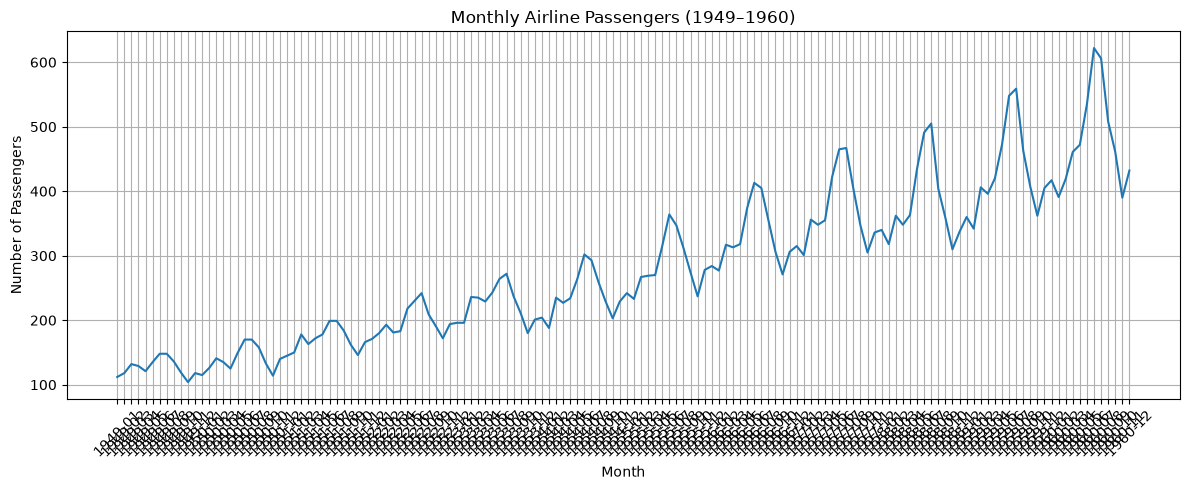

In [59]:
plt.figure(figsize=(12, 5))
plt.plot(df_rnn["Month"], df_rnn["Passengers"])
plt.title("Monthly Airline Passengers (1949–1960)")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [60]:
passengers = df_rnn[["Passengers"]].values.astype("float32")

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_passengers = scaler.fit_transform(passengers)

print("Original shape:", passengers.shape)
print("Normalized shape:", scaled_passengers.shape)
print("Normalized range:", scaled_passengers.min(), "to", scaled_passengers.max())

Original shape: (144, 1)
Normalized shape: (144, 1)
Normalized range: 0.0 to 1.0


In [61]:
look_back = 12

X, y = [], []

for i in range(len(scaled_passengers) - look_back):
    X.append(scaled_passengers[i:i + look_back, 0])
    y.append(scaled_passengers[i + look_back, 0])

X = np.array(X)
y = np.array(y)

X = X.reshape(X.shape[0], X.shape[1], 1)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (132, 12, 1)
y shape: (132,)


In [62]:
split_index = int(len(X) * 0.8)

X_train_rnn = X[:split_index]
X_test_rnn = X[split_index:]

y_train_rnn = y[:split_index]
y_test_rnn = y[split_index:]

print("Training samples:", X_train_rnn.shape[0])
print("Testing samples:", X_test_rnn.shape[0])

Training samples: 105
Testing samples: 27


In [63]:
rnn_model = Sequential([
    SimpleRNN(
        50,
        activation="tanh",
        input_shape=(12, 1)
    ),
    Dense(1)
])

rnn_model.compile(
    optimizer="adam",
    loss="mse"
)

rnn_model.summary()

c:\Users\patel\OneDrive\Desktop\R&W\Deep Learning\Deep learning practical exam set A\DeepLearning-Set-A\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

### Step 4: RNN — Airline Passenger Forecasting

**Objective:** Predict the next month's passenger count using the previous 12 months.

- **MinMaxScaler:** Normalizes passenger counts to the range 0–1.
- **SimpleRNN:** Learns sequential patterns from previous months.
- **Dense(1):** Predicts one passenger-count value.
- **MSE:** Measures the squared prediction error.

The data is split chronologically without shuffling to preserve time order.

In [64]:
rnn_history = rnn_model.fit(
    X_train_rnn,
    y_train_rnn,
    epochs=50,
    batch_size=16,
    verbose=1
)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1942  
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0410 
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0067 
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0093 
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0032 
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0032 
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0020 
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0020 
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0017 
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0017     
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0016 
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0015 
Epoch 13/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0014 
Epoch 14/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0014     
Epoch 15/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0014 
Epoch 16/50
7/7 ━━━━━━━━━

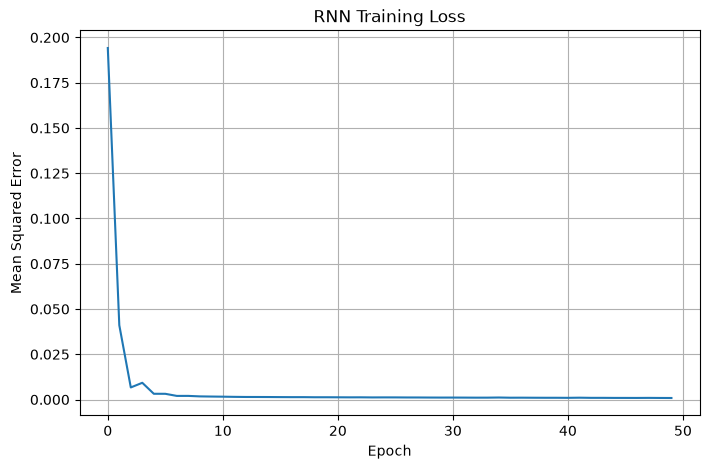

In [65]:
plt.figure(figsize=(8, 5))
plt.plot(rnn_history.history["loss"])
plt.title("RNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True)
plt.show()

In [66]:
train_predictions = rnn_model.predict(X_train_rnn, verbose=0)
test_predictions = rnn_model.predict(X_test_rnn, verbose=0)

train_predictions = scaler.inverse_transform(train_predictions)
test_predictions = scaler.inverse_transform(test_predictions)

y_train_actual = scaler.inverse_transform(
    y_train_rnn.reshape(-1, 1)
)
y_test_actual = scaler.inverse_transform(
    y_test_rnn.reshape(-1, 1)
)

rmse = np.sqrt(mean_squared_error(y_test_actual, test_predictions))

print(f"Test RMSE: {rmse:.2f} passengers")

Test RMSE: 44.36 passengers


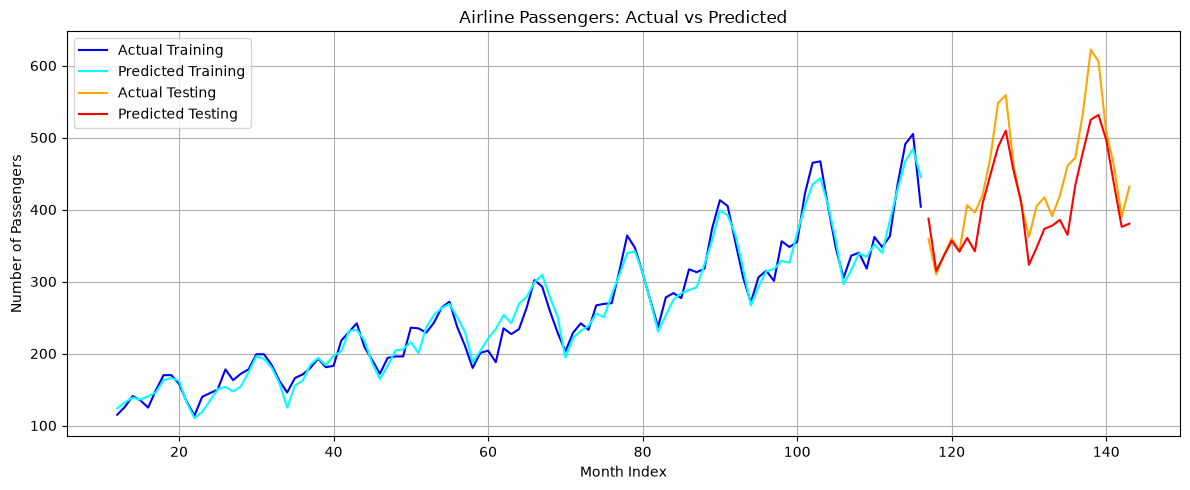

In [67]:
plt.figure(figsize=(12, 5))

train_index = np.arange(look_back, look_back + len(train_predictions))
test_index = np.arange(
    look_back + len(train_predictions),
    look_back + len(train_predictions) + len(test_predictions)
)

plt.plot(train_index, y_train_actual.ravel(),
         label="Actual Training", color="blue")
plt.plot(train_index, train_predictions.ravel(),
         label="Predicted Training", color="cyan")

plt.plot(test_index, y_test_actual.ravel(),
         label="Actual Testing", color="orange")
plt.plot(test_index, test_predictions.ravel(),
         label="Predicted Testing", color="red")

plt.title("Airline Passengers: Actual vs Predicted")
plt.xlabel("Month Index")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [68]:
rnn_model.save("rnn_airline_model.h5")
print("RNN model saved successfully!")

RNN model saved successfully!


### 4.4 Save & Reflect

- **Recurrent connection:** Allows the RNN to learn from sequential information.
- **No shuffling:** Preserves chronological order and prevents future observations from being mixed into earlier periods.
- **RMSE:** Measures prediction error in passenger-count units; lower RMSE indicates more accurate predictions.
- **Model saving:** The trained model is saved as `rnn_airline_model.h5`.

# Step 5 - Transformers

In [69]:
pip install transformers torch

  Using cached huggingface_hub-2.2.0-py3-none-any.whl.metadata (16 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-win_amd64.whl.metadata (10 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.7.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.8 MB 1.3 MB/s eta 0:00:10
   -- ------------------------------------- 0.8/12.8 MB 1.5 MB/s eta 0:00:08
   --- ------------------------------------ 1.0/12.8 MB 1.5 MB/s eta 0:00:08
   ---- ----------------------------------- 1.3/12.8 MB 1.5 MB/s eta 0:00:08
   ---- ----------------------------------- 1.6/12.8 MB 1.4 MB/s eta 0:00:09
   ----- ---------------------------------- 1.8/12.8 MB 1.4 MB/s eta 0:00:08
   ------ --------------------------------- 

In [70]:
import pandas as pd
import matplotlib.pyplot as plt

from transformers import pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


In [71]:
classifier = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

print("Sentiment model loaded successfully!")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Sentiment model loaded successfully!


In [72]:
reviews = [
    "The film was absolutely brilliant and moving.",
    "I loved every moment of this wonderful movie.",
    "The actors delivered outstanding performances.",
    "An entertaining film with a beautiful story.",
    "The movie was fantastic from beginning to end.",
    "Amazing visuals and excellent direction.",
    "This film made me laugh and smile.",
    "A masterpiece with a powerful message.",
    "The soundtrack and acting were excellent.",
    "I would happily watch this movie again.",

    "This was the worst movie I have ever seen.",
    "The story was boring and poorly written.",
    "Terrible acting and disappointing direction.",
    "I hated this film completely.",
    "The movie wasted my time.",
    "The plot was confusing and dull.",
    "Awful dialogue and weak performances.",
    "Nothing about this movie was enjoyable.",
    "The ending was terrible and disappointing.",
    "I would never recommend this film.",

    "The acting was decent but the plot was weak.",
    "The movie was okay, nothing special.",
    "The visuals were good but the story was average.",
    "The film had some interesting and boring parts.",
    "It was a movie with a predictable ending."
]

true_sentiments = (
    ["POS"] * 10 +
    ["NEG"] * 10 +
    ["NEU"] * 5
)

print("Total reviews:", len(reviews))
print("Total labels:", len(true_sentiments))

Total reviews: 25
Total labels: 25


In [73]:
results = classifier(reviews)

predicted_labels = [result["label"] for result in results]
confidence_scores = [result["score"] for result in results]

df_sentiment = pd.DataFrame({
    "Sentence": reviews,
    "True_Sentiment": true_sentiments,
    "Predicted_Label": predicted_labels,
    "Confidence_Score": confidence_scores
})

display(df_sentiment)

,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
0,The film was absolutely brilliant and moving.,POS,POSITIVE,0.999887
1,I loved every moment of this wonderful movie.,POS,POSITIVE,0.999883
2,The actors delivered outstanding performances.,POS,POSITIVE,0.999867
3,An entertaining film with a beautiful story.,POS,POSITIVE,0.999884
4,The movie was fantastic from beginning to end.,POS,POSITIVE,0.999882
5,Amazing visuals and excellent direction.,POS,POSITIVE,0.999872
6,This film made me laugh and smile.,POS,POSITIVE,0.999864
7,A masterpiece with a powerful message.,POS,POSITIVE,0.999888
8,The soundtrack and acting were excellent.,POS,POSITIVE,0.999853
9,I would happily watch this movie again.,POS,POSITIVE,0.999719


In [74]:
correct = 0

for i in range(20):
    expected = "POSITIVE" if true_sentiments[i] == "POS" else "NEGATIVE"

    if predicted_labels[i] == expected:
        correct += 1

print("Correct predictions:", correct, "out of 20")
print(f"Accuracy: {correct / 20 * 100:.2f}%")

Correct predictions: 19 out of 20
Accuracy: 95.00%


In [75]:
display(df_sentiment.iloc[20:25])

,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
20,The acting was decent but the plot was weak.,NEU,NEGATIVE,0.998836
21,"The movie was okay, nothing special.",NEU,NEGATIVE,0.992512
22,The visuals were good but the story was average.,NEU,POSITIVE,0.579828
23,The film had some interesting and boring parts.,NEU,NEGATIVE,0.995469
24,It was a movie with a predictable ending.,NEU,NEGATIVE,0.999678


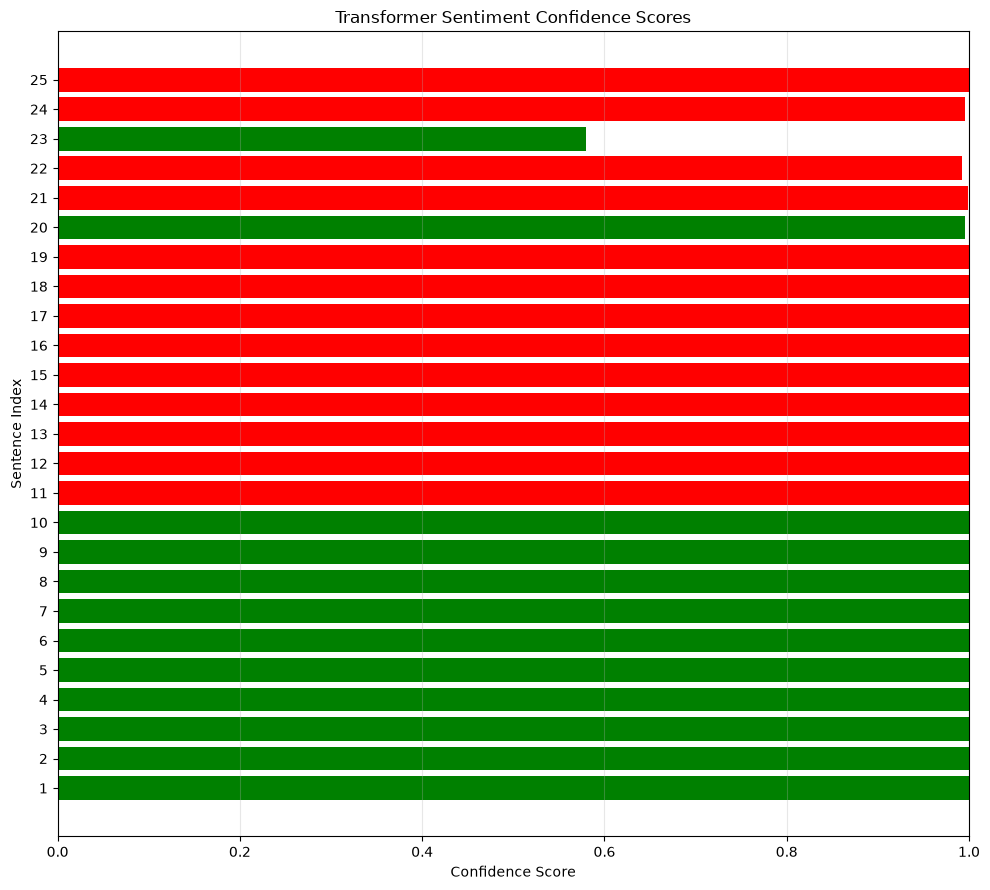

<Figure size 640x480 with 0 Axes>

In [78]:
colors = [
    "green" if label == "POSITIVE" else "red"
    for label in predicted_labels
]

plt.figure(figsize=(10, 9))
plt.barh(range(1, 26), confidence_scores, color=colors)

plt.yticks(range(1, 26))
plt.xlabel("Confidence Score")
plt.ylabel("Sentence Index")
plt.title("Transformer Sentiment Confidence Scores")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

plt.savefig("outputs/transformer_sentiment.png", dpi=300, bbox_inches="tight")

### Step 5: Transformers — Sentiment Analysis

**Objective:** Classify 25 movie reviews using a pre-trained Hugging Face Transformer.

- **Transformer:** Uses attention mechanisms to process text.
- **Pre-trained:** Learns language patterns from existing training data.
- **Fine-tuned:** Further trained for a specific task, such as sentiment classification.
- **Inference:** Predicts sentiment without training a new model.
- **Limitations:** The English sentiment model may misunderstand Indian-English expressions, slang, sarcasm, and ambiguous reviews.

**Result:** Predictions and confidence scores are stored in a DataFrame and visualized in a horizontal bar chart.

# Step 6 - Comparison

## Step 6: Model Comparison

| Model | Task | Main Architecture | Output |
|---|---|---|---|
| ANN | Diabetes prediction | Dense neural network | Binary classification |
| OpenCV | Image preprocessing | Resize, grayscale, blur, Canny, contours | Processed images |
| CNN | CIFAR-10 classification | Convolutional neural network | 10 image classes |
| RNN | Airline passenger forecasting | SimpleRNN | Passenger prediction |
| Transformer | Sentiment analysis | Pre-trained DistilBERT | Positive/negative sentiment |

### Reflection

- ANN performs classification using connected neural-network layers.
- OpenCV extracts useful visual features through image-processing operations.
- CNN learns spatial features for image classification.
- RNN uses sequential information to forecast time-series data.
- Transformers use attention mechanisms to understand text.
- Model performance depends on data quality, preprocessing, architecture, and training settings.
- Each technique is suited to a different type of problem.